In [1]:
from statsbombpy import sb
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.metrics.pairwise import cosine_similarity

In [2]:
competitions = sb.competitions()

print(competitions.info)

C:\Users\mahmo\Downloads\ScoutIQ\.venv\Lib\site-packages\statsbombpy\api_client.py:27: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(


<bound method DataFrame.info of     competition_id  season_id   country_name        competition_name  \
0                9        281        Germany           1. Bundesliga   
1                9         27        Germany           1. Bundesliga   
2             1267        107         Africa  African Cup of Nations   
3               16          4         Europe        Champions League   
4               16          1         Europe        Champions League   
..             ...        ...            ...                     ...   
75              35         75         Europe      UEFA Europa League   
76              53        315         Europe       UEFA Women's Euro   
77              53        106         Europe       UEFA Women's Euro   
78              72        107  International       Women's World Cup   
79              72         30  International       Women's World Cup   

   competition_gender  competition_youth  competition_international  \
0                male           

In [3]:
print(competitions.columns)

Index(['competition_id', 'season_id', 'country_name', 'competition_name',
       'competition_gender', 'competition_youth', 'competition_international',
       'season_name', 'match_updated', 'match_updated_360',
       'match_available_360', 'match_available'],
      dtype='str')


In [4]:
print(competitions.head(5))

   competition_id  season_id country_name        competition_name  \
0               9        281      Germany           1. Bundesliga   
1               9         27      Germany           1. Bundesliga   
2            1267        107       Africa  African Cup of Nations   
3              16          4       Europe        Champions League   
4              16          1       Europe        Champions League   

  competition_gender  competition_youth  competition_international  \
0               male              False                      False   
1               male              False                      False   
2               male              False                       True   
3               male              False                      False   
4               male              False                      False   

  season_name               match_updated           match_updated_360  \
0   2023/2024  2024-09-28T20:46:38.893391  2025-11-15T23:17:41.827093   
1   2015/2016  202

In [5]:
matches = sb.matches(competition_id=9, season_id=281)

C:\Users\mahmo\Downloads\ScoutIQ\.venv\Lib\site-packages\statsbombpy\api_client.py:27: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(


In [6]:
teams = matches['home_team']
print(teams.nunique())

18


In [7]:
print(matches['match_id'].iloc[0])

3895292


In [8]:
events = sb.events(match_id=3895292)
print(events)

     50_50 ball_receipt_outcome ball_recovery_offensive  \
0      NaN                  NaN                     NaN   
1      NaN                  NaN                     NaN   
2      NaN                  NaN                     NaN   
3      NaN                  NaN                     NaN   
4      NaN                  NaN                     NaN   
...    ...                  ...                     ...   
3838   NaN                  NaN                     NaN   
3839   NaN                  NaN                     NaN   
3840   NaN                  NaN                     NaN   
3841   NaN                  NaN                     NaN   
3842   NaN                  NaN                     NaN   

     ball_recovery_recovery_failure block_deflection block_offensive  \
0                               NaN              NaN             NaN   
1                               NaN              NaN             NaN   
2                               NaN              NaN             NaN   
3  

In [9]:
events[['player', 'team', 'type']].head(10)

,player,team,type
0,NaN,Union Berlin,Starting XI
1,NaN,Bayer Leverkusen,Starting XI
2,NaN,Bayer Leverkusen,Half Start
3,NaN,Union Berlin,Half Start
4,NaN,Bayer Leverkusen,Half Start
5,NaN,Union Berlin,Half Start
6,Brenden Aaronson,Union Berlin,Pass
7,András Schäfer,Union Berlin,Pass
8,Danilho Doekhi,Union Berlin,Pass
9,Robin Gosens,Union Berlin,Pass


In [10]:
events['type'].value_counts()

type
Pass                 1080
Ball Receipt*        1041
Carry                 905
Pressure              278
Ball Recovery         101
Duel                   76
Block                  45
Clearance              44
Goal Keeper            37
Dribble                29
Shot                   29
Miscontrol             26
Foul Committed         26
Foul Won               25
Dispossessed           23
Interception           20
Dribbled Past          15
Injury Stoppage        10
50/50                   8
Substitution            8
Half Start              4
Half End                4
Tactical Shift          4
Starting XI             2
Player Off              1
Referee Ball-Drop       1
Player On               1
Name: count, dtype: int64

In [11]:
events['player'].nunique()

30

In [12]:
passes = events[events['type'] == "Pass"].groupby(events['player']).size().sort_values(ascending=False)
print(passes)

player
Piero Martín Hincapié Reyna          95
Jonathan Tah                         93
Granit Xhaka                         92
Alejandro Grimaldo García            91
Robert Andrich                       72
Odilon Kossonou                      67
Florian Wirtz                        66
Frederik Rønnow                      48
Kevin Vogt                           43
Diogo Filipe Monteiro Pinto Leite    39
Nathan Tella                         34
Amine Adli                           29
Danilho Doekhi                       28
Josip Juranović                      27
Robin Gosens                         27
Lukáš Hrádecký                       25
András Schäfer                       24
Christopher Trimmel                  24
Brenden Aaronson                     23
Lucas Tousart                        22
Aïssa Bilal Laïdouni                 18
Rani Khedira                         18
Alex Král                            17
Borja Iglesias Quintas               14
Adam Hložek                      

In [13]:
pass_events = events[events['type'] == 'Pass'].copy()

print(type(pass_events))
print(pass_events.shape)

<class 'pandas.DataFrame'>
(1080, 91)


In [14]:
pass_events['pass_outcome'].value_counts(dropna=False)

pass_outcome
NaN                 906
Incomplete          144
Out                  18
Unknown               8
Pass Offside          2
Injury Clearance      2
Name: count, dtype: int64

In [15]:
completed_passes = pass_events[pass_events['pass_outcome'].isna()].groupby('player').size().sort_values(ascending=False)
print(completed_passes)
print(completed_passes.sum())

player
Piero Martín Hincapié Reyna          89
Jonathan Tah                         86
Granit Xhaka                         83
Alejandro Grimaldo García            71
Robert Andrich                       67
Odilon Kossonou                      64
Florian Wirtz                        56
Kevin Vogt                           40
Diogo Filipe Monteiro Pinto Leite    33
Frederik Rønnow                      33
Nathan Tella                         28
Lukáš Hrádecký                       24
Danilho Doekhi                       23
Amine Adli                           22
Brenden Aaronson                     19
Robin Gosens                         18
Josip Juranović                      18
Lucas Tousart                        17
András Schäfer                       17
Aïssa Bilal Laïdouni                 16
Rani Khedira                         15
Christopher Trimmel                  14
Alex Král                            13
Adam Hložek                          11
Victor Okoh Boniface             

In [16]:
passing_accuracy = (completed_passes / passes) * 100
passing_accuracy = passing_accuracy.round(2)
print(passing_accuracy.sort_values(ascending=False))

player
Lukáš Hrádecký                       96.00
Odilon Kossonou                      95.52
Piero Martín Hincapié Reyna          93.68
Robert Andrich                       93.06
Kevin Vogt                           93.02
Jonathan Tah                         92.47
Adam Hložek                          91.67
Granit Xhaka                         90.22
Jeremie Frimpong                     88.89
Aïssa Bilal Laïdouni                 88.89
Victor Okoh Boniface                 88.89
Florian Wirtz                        84.85
Diogo Filipe Monteiro Pinto Leite    84.62
Rani Khedira                         83.33
Brenden Aaronson                     82.61
Nathan Tella                         82.35
Danilho Doekhi                       82.14
Alejandro Grimaldo García            78.02
Lucas Tousart                        77.27
Alex Král                            76.47
Amine Adli                           75.86
András Schäfer                       70.83
Frederik Rønnow                      68.75
Robi

In [17]:
player_stats = pd.DataFrame({
    'passes_attempted': passes,
    'passes_completed': completed_passes,
    'passing_accuracy': passing_accuracy
})
print(player_stats.head())

                           passes_attempted  passes_completed  \
player                                                          
Adam Hložek                              12                11   
Alejandro Grimaldo García                91                71   
Alex Král                                17                13   
Amine Adli                               29                22   
András Schäfer                           24                17   

                           passing_accuracy  
player                                       
Adam Hložek                           91.67  
Alejandro Grimaldo García             78.02  
Alex Král                             76.47  
Amine Adli                            75.86  
András Schäfer                        70.83  


In [18]:
shots_attempted = events[events['type'] == "Shot"].groupby(events['player']).size().sort_values(ascending=False)

In [19]:
player_stats['shots_attempted'] = shots_attempted
player_stats['shots_attempted'] = player_stats['shots_attempted'].fillna(0).astype(int)
print(player_stats.head())

                           passes_attempted  passes_completed  \
player                                                          
Adam Hložek                              12                11   
Alejandro Grimaldo García                91                71   
Alex Král                                17                13   
Amine Adli                               29                22   
András Schäfer                           24                17   

                           passing_accuracy  shots_attempted  
player                                                        
Adam Hložek                           91.67                1  
Alejandro Grimaldo García             78.02                3  
Alex Král                             76.47                2  
Amine Adli                            75.86                2  
András Schäfer                        70.83                1  


In [20]:
print(player_stats[['shots_attempted']])
print(player_stats['shots_attempted'].sum())

                                   shots_attempted
player                                            
Adam Hložek                                      1
Alejandro Grimaldo García                        3
Alex Král                                        2
Amine Adli                                       2
András Schäfer                                   1
Aïssa Bilal Laïdouni                             0
Benedict Hollerbach                              0
Borja Iglesias Quintas                           2
Brenden Aaronson                                 0
Christopher Trimmel                              0
Danilho Doekhi                                   0
Diogo Filipe Monteiro Pinto Leite                1
Florian Wirtz                                    2
Frederik Rønnow                                  2
Granit Xhaka                                     1
Jeremie Frimpong                                 2
Jonathan Tah                                     1
Josip Juranović                

In [21]:
shot_events = events[events['type'] == "Shot"]
print(shot_events['shot_outcome'].value_counts(dropna=False))

shot_outcome
Blocked    11
Saved       7
Off T       6
Wayward     4
Goal        1
Name: count, dtype: int64


In [22]:
goal_events = shot_events[shot_events['shot_outcome'] == "Goal"].groupby('player').size()
print(goal_events)

player
Florian Wirtz    1
dtype: int64


In [23]:
player_stats['goals_scored'] = goal_events
player_stats['goals_scored'] = player_stats['goals_scored'].fillna(0).astype(int)
print(player_stats.head())

                           passes_attempted  passes_completed  \
player                                                          
Adam Hložek                              12                11   
Alejandro Grimaldo García                91                71   
Alex Král                                17                13   
Amine Adli                               29                22   
András Schäfer                           24                17   

                           passing_accuracy  shots_attempted  goals_scored  
player                                                                      
Adam Hložek                           91.67                1             0  
Alejandro Grimaldo García             78.02                3             0  
Alex Král                             76.47                2             0  
Amine Adli                            75.86                2             0  
András Schäfer                        70.83                1             0  


In [24]:
events[(events['type'] == 'Shot') & (events['player'] == 'Frederik Rønnow')][['player', 'type', 'shot_outcome', 'minute']]

,player,type,shot_outcome,minute
3696,Frederik Rønnow,Shot,Blocked,96
3697,Frederik Rønnow,Shot,Wayward,96


In [25]:
interceptions_events = events[events['type'] == "Interception"].groupby('player').size()
print(interceptions_events)
print(interceptions_events.sum())

player
Alex Král                            1
András Schäfer                       1
Benedict Hollerbach                  1
Danilho Doekhi                       1
Diogo Filipe Monteiro Pinto Leite    1
Granit Xhaka                         1
Jonathan Tah                         2
Josip Juranović                      2
Lucas Tousart                        4
Nathan Tella                         1
Odilon Kossonou                      2
Robert Andrich                       2
Victor Okoh Boniface                 1
dtype: int64
20


In [26]:
player_stats['interceptions'] = interceptions_events
player_stats['interceptions'] = player_stats['interceptions'].fillna(0).astype(int)
print(player_stats.head())

                           passes_attempted  passes_completed  \
player                                                          
Adam Hložek                              12                11   
Alejandro Grimaldo García                91                71   
Alex Král                                17                13   
Amine Adli                               29                22   
András Schäfer                           24                17   

                           passing_accuracy  shots_attempted  goals_scored  \
player                                                                       
Adam Hložek                           91.67                1             0   
Alejandro Grimaldo García             78.02                3             0   
Alex Král                             76.47                2             0   
Amine Adli                            75.86                2             0   
András Schäfer                        70.83                1             0  

In [27]:
ballrecovery_events = events[events['type'] == "Ball Recovery"].groupby('player').size()
print(ballrecovery_events)
print(ballrecovery_events.sum())

player
Adam Hložek                          2
Alejandro Grimaldo García            3
Alex Král                            2
Amine Adli                           2
András Schäfer                       5
Aïssa Bilal Laïdouni                 2
Benedict Hollerbach                  2
Borja Iglesias Quintas               2
Brenden Aaronson                     9
Christopher Trimmel                  3
Diogo Filipe Monteiro Pinto Leite    6
Florian Wirtz                        6
Frederik Rønnow                      7
Granit Xhaka                         5
Jeremie Frimpong                     1
Jonathan Tah                         4
Kevin Vogt                           3
Lucas Tousart                        6
Lukáš Hrádecký                       3
Mikkel Kaufmann                      1
Nathan Tella                         7
Odilon Kossonou                      5
Piero Martín Hincapié Reyna          1
Rani Khedira                         1
Robert Andrich                       7
Robin Gosens      

In [28]:
player_stats['ball_recoveries'] = ballrecovery_events
player_stats['ball_recoveries'] = player_stats['ball_recoveries'].fillna(0).astype(int)
print(player_stats.head())

                           passes_attempted  passes_completed  \
player                                                          
Adam Hložek                              12                11   
Alejandro Grimaldo García                91                71   
Alex Král                                17                13   
Amine Adli                               29                22   
András Schäfer                           24                17   

                           passing_accuracy  shots_attempted  goals_scored  \
player                                                                       
Adam Hložek                           91.67                1             0   
Alejandro Grimaldo García             78.02                3             0   
Alex Král                             76.47                2             0   
Amine Adli                            75.86                2             0   
András Schäfer                        70.83                1             0  

In [29]:
dribble_events = events[events['type'] == "Dribble"]
print(dribble_events['dribble_outcome'].value_counts(dropna=False))

dribble_outcome
Incomplete    16
Complete      13
Name: count, dtype: int64


In [30]:
dribble_events = events[events['type'] == 'Dribble'].copy()
dribble_attempted = dribble_events.groupby('player').size()
print(dribble_attempted)
print(dribble_attempted.sum())

player
Alejandro Grimaldo García            1
Alex Král                            1
Amine Adli                           1
András Schäfer                       1
Benedict Hollerbach                  2
Brenden Aaronson                     2
Diogo Filipe Monteiro Pinto Leite    2
Florian Wirtz                        4
Granit Xhaka                         1
Jeremie Frimpong                     2
Josip Juranović                      1
Lucas Tousart                        3
Nathan Tella                         3
Odilon Kossonou                      2
Piero Martín Hincapié Reyna          1
Robert Andrich                       2
dtype: int64
29


In [31]:
dribbles_completed = dribble_events[dribble_events['dribble_outcome'] == "Complete"].groupby('player').size().sort_values(ascending=False)
print(dribbles_completed)
print(dribbles_completed.sum())

player
Odilon Kossonou        2
Nathan Tella           2
Lucas Tousart          2
Alex Král              1
Amine Adli             1
Benedict Hollerbach    1
Josip Juranović        1
Jeremie Frimpong       1
Granit Xhaka           1
Robert Andrich         1
dtype: int64
13


In [32]:
player_stats['dribbles_attempted'] = dribble_attempted
player_stats['dribbles_attempted'] = player_stats['dribbles_attempted'].fillna(0).astype(int)
player_stats['dribbles_completed'] = dribbles_completed
player_stats['dribbles_completed'] = player_stats['dribbles_completed'].fillna(0).astype(int)
print(player_stats.head())

                           passes_attempted  passes_completed  \
player                                                          
Adam Hložek                              12                11   
Alejandro Grimaldo García                91                71   
Alex Král                                17                13   
Amine Adli                               29                22   
András Schäfer                           24                17   

                           passing_accuracy  shots_attempted  goals_scored  \
player                                                                       
Adam Hložek                           91.67                1             0   
Alejandro Grimaldo García             78.02                3             0   
Alex Král                             76.47                2             0   
Amine Adli                            75.86                2             0   
András Schäfer                        70.83                1             0  

In [33]:
dribble_success_pct = (dribbles_completed / dribble_attempted) * 100
dribble_success_pct = dribble_success_pct.round(2)
print(dribble_success_pct)

player
Alejandro Grimaldo García               NaN
Alex Král                            100.00
Amine Adli                           100.00
András Schäfer                          NaN
Benedict Hollerbach                   50.00
Brenden Aaronson                        NaN
Diogo Filipe Monteiro Pinto Leite       NaN
Florian Wirtz                           NaN
Granit Xhaka                         100.00
Jeremie Frimpong                      50.00
Josip Juranović                      100.00
Lucas Tousart                         66.67
Nathan Tella                          66.67
Odilon Kossonou                      100.00
Piero Martín Hincapié Reyna             NaN
Robert Andrich                        50.00
dtype: float64


In [34]:
player_stats['dribble_success_pct'] = dribble_success_pct
player_stats['dribble_success_pct'] = player_stats['dribble_success_pct'].fillna(0)
print(player_stats.head())

                           passes_attempted  passes_completed  \
player                                                          
Adam Hložek                              12                11   
Alejandro Grimaldo García                91                71   
Alex Král                                17                13   
Amine Adli                               29                22   
András Schäfer                           24                17   

                           passing_accuracy  shots_attempted  goals_scored  \
player                                                                       
Adam Hložek                           91.67                1             0   
Alejandro Grimaldo García             78.02                3             0   
Alex Král                             76.47                2             0   
Amine Adli                            75.86                2             0   
András Schäfer                        70.83                1             0  

In [35]:
print(player_stats[['dribbles_attempted', 'dribbles_completed', 'dribble_success_pct']])

                                   dribbles_attempted  dribbles_completed  \
player                                                                      
Adam Hložek                                         0                   0   
Alejandro Grimaldo García                           1                   0   
Alex Král                                           1                   1   
Amine Adli                                          1                   1   
András Schäfer                                      1                   0   
Aïssa Bilal Laïdouni                                0                   0   
Benedict Hollerbach                                 2                   1   
Borja Iglesias Quintas                              0                   0   
Brenden Aaronson                                    2                   0   
Christopher Trimmel                                 0                   0   
Danilho Doekhi                                      0                   0   

In [36]:
substitution_events = events[events['type'] == 'Substitution'].copy()

print(substitution_events[['player', 'minute', 'substitution_replacement']])

                      player  minute substitution_replacement
3824             Adam Hložek      31               Amine Adli
3825         Yorbe Vertessen      45          Mikkel Kaufmann
3826            Rani Khedira      61     Aïssa Bilal Laïdouni
3827     Christopher Trimmel      62          Josip Juranović
3828          András Schäfer      62                Alex Král
3829  Borja Iglesias Quintas      66     Victor Okoh Boniface
3830        Brenden Aaronson      77      Benedict Hollerbach
3831            Nathan Tella      78         Jeremie Frimpong


In [37]:
starting_events = events[events['type'] == 'Starting XI']
print(starting_events[['team', 'tactics']])
print(starting_events.iloc[0]['tactics'])

               team                                            tactics
0      Union Berlin  {'formation': 3511, 'lineup': [{'player': {'id...
1  Bayer Leverkusen  {'formation': 3421, 'lineup': [{'player': {'id...
{'formation': 3511, 'lineup': [{'player': {'id': 12420, 'name': 'Frederik Rønnow'}, 'position': {'id': 1, 'name': 'Goalkeeper'}, 'jersey_number': 1}, {'player': {'id': 18789, 'name': 'Danilho Doekhi'}, 'position': {'id': 3, 'name': 'Right Center Back'}, 'jersey_number': 5}, {'player': {'id': 8397, 'name': 'Kevin Vogt'}, 'position': {'id': 4, 'name': 'Center Back'}, 'jersey_number': 2}, {'player': {'id': 11175, 'name': 'Diogo Filipe Monteiro Pinto Leite'}, 'position': {'id': 5, 'name': 'Left Center Back'}, 'jersey_number': 4}, {'player': {'id': 9164, 'name': 'Christopher Trimmel'}, 'position': {'id': 7, 'name': 'Right Wing Back'}, 'jersey_number': 28}, {'player': {'id': 6985, 'name': 'Robin Gosens'}, 'position': {'id': 8, 'name': 'Left Wing Back'}, 'jersey_number': 6}, {'player

In [38]:
union_lineup = starting_events.iloc[0]['tactics']['lineup']
print(union_lineup)

[{'player': {'id': 12420, 'name': 'Frederik Rønnow'}, 'position': {'id': 1, 'name': 'Goalkeeper'}, 'jersey_number': 1}, {'player': {'id': 18789, 'name': 'Danilho Doekhi'}, 'position': {'id': 3, 'name': 'Right Center Back'}, 'jersey_number': 5}, {'player': {'id': 8397, 'name': 'Kevin Vogt'}, 'position': {'id': 4, 'name': 'Center Back'}, 'jersey_number': 2}, {'player': {'id': 11175, 'name': 'Diogo Filipe Monteiro Pinto Leite'}, 'position': {'id': 5, 'name': 'Left Center Back'}, 'jersey_number': 4}, {'player': {'id': 9164, 'name': 'Christopher Trimmel'}, 'position': {'id': 7, 'name': 'Right Wing Back'}, 'jersey_number': 28}, {'player': {'id': 6985, 'name': 'Robin Gosens'}, 'position': {'id': 8, 'name': 'Left Wing Back'}, 'jersey_number': 6}, {'player': {'id': 9402, 'name': 'Rani Khedira'}, 'position': {'id': 10, 'name': 'Center Defensive Midfield'}, 'jersey_number': 8}, {'player': {'id': 3117, 'name': 'Lucas Tousart'}, 'position': {'id': 13, 'name': 'Right Center Midfield'}, 'jersey_numbe

In [39]:
for player in union_lineup:
    print(player['player']['name'], "-", player['position']['name'])

Frederik Rønnow - Goalkeeper
Danilho Doekhi - Right Center Back
Kevin Vogt - Center Back
Diogo Filipe Monteiro Pinto Leite - Left Center Back
Christopher Trimmel - Right Wing Back
Robin Gosens - Left Wing Back
Rani Khedira - Center Defensive Midfield
Lucas Tousart - Right Center Midfield
András Schäfer - Left Center Midfield
Brenden Aaronson - Center Attacking Midfield
Yorbe Vertessen - Center Forward


In [40]:
starting_players = []

for index, row in starting_events.iterrows():
    player_list = row['tactics']['lineup']
    
    for player in player_list:
        player_info = {
            'player': player['player']['name'],
            'team': row['team'],
            'position': player['position']['name']
        }

        
        starting_players.append(player_info)

starting_df = pd.DataFrame(starting_players)
print(starting_df.shape)
print(starting_df.head())

(22, 3)
                              player          team           position
0                    Frederik Rønnow  Union Berlin         Goalkeeper
1                     Danilho Doekhi  Union Berlin  Right Center Back
2                         Kevin Vogt  Union Berlin        Center Back
3  Diogo Filipe Monteiro Pinto Leite  Union Berlin   Left Center Back
4                Christopher Trimmel  Union Berlin    Right Wing Back


In [41]:
print(substitution_events[['player', 'team', 'minute', 'substitution_replacement']].head())

                   player              team  minute substitution_replacement
3824          Adam Hložek  Bayer Leverkusen      31               Amine Adli
3825      Yorbe Vertessen      Union Berlin      45          Mikkel Kaufmann
3826         Rani Khedira      Union Berlin      61     Aïssa Bilal Laïdouni
3827  Christopher Trimmel      Union Berlin      62          Josip Juranović
3828       András Schäfer      Union Berlin      62                Alex Král


In [42]:
substitutes_df = substitution_events[
    ['substitution_replacement', 'team', 'minute']
].copy()

substitutes_df = substitutes_df.rename(columns={
    'substitution_replacement': 'player',
    'minute': 'entered_minute'
})

print(substitutes_df.shape)
print(substitutes_df.head())

(8, 3)
                    player              team  entered_minute
3824            Amine Adli  Bayer Leverkusen              31
3825       Mikkel Kaufmann      Union Berlin              45
3826  Aïssa Bilal Laïdouni      Union Berlin              61
3827       Josip Juranović      Union Berlin              62
3828             Alex Král      Union Berlin              62


In [43]:
all_players = pd.concat([starting_df, substitutes_df], ignore_index=True)
print(all_players.shape)
print(all_players.columns)

(30, 4)
Index(['player', 'team', 'position', 'entered_minute'], dtype='str')


In [44]:
all_players['is_starter'] = all_players['entered_minute'].isna()
print(all_players['is_starter'].value_counts())

is_starter
True     22
False     8
Name: count, dtype: int64


In [45]:
exiting_players = substitution_events[['player', 'minute']]
exiting_players = exiting_players.rename(columns={'minute': 'exit_minute'})
all_players = all_players.merge(exiting_players, on='player', how='left')

print(all_players.shape)
print(all_players[['player', 'is_starter', 'entered_minute', 'exit_minute']].head(10))
print(all_players['exit_minute'].notna().sum())

(30, 6)
                              player  is_starter  entered_minute  exit_minute
0                    Frederik Rønnow        True             NaN          NaN
1                     Danilho Doekhi        True             NaN          NaN
2                         Kevin Vogt        True             NaN          NaN
3  Diogo Filipe Monteiro Pinto Leite        True             NaN          NaN
4                Christopher Trimmel        True             NaN         62.0
5                       Robin Gosens        True             NaN          NaN
6                       Rani Khedira        True             NaN         61.0
7                      Lucas Tousart        True             NaN          NaN
8                     András Schäfer        True             NaN         62.0
9                   Brenden Aaronson        True             NaN         77.0
8


In [46]:
match_end_minute = events['minute'].max()
print(match_end_minute)

97


In [47]:
all_players['start_minute'] = all_players['entered_minute'].fillna(0)

all_players['end_minute'] = all_players['exit_minute'].fillna(match_end_minute)

all_players['minutes_played'] = all_players['end_minute'] - all_players['start_minute']

print(all_players[['player', 'start_minute', 'end_minute', 'minutes_played']])

                               player  start_minute  end_minute  \
0                     Frederik Rønnow           0.0        97.0   
1                      Danilho Doekhi           0.0        97.0   
2                          Kevin Vogt           0.0        97.0   
3   Diogo Filipe Monteiro Pinto Leite           0.0        97.0   
4                 Christopher Trimmel           0.0        62.0   
5                        Robin Gosens           0.0        97.0   
6                        Rani Khedira           0.0        61.0   
7                       Lucas Tousart           0.0        97.0   
8                      András Schäfer           0.0        62.0   
9                    Brenden Aaronson           0.0        77.0   
10                    Yorbe Vertessen           0.0        45.0   
11                     Lukáš Hrádecký           0.0        97.0   
12                    Odilon Kossonou           0.0        97.0   
13                       Jonathan Tah           0.0        97.

In [48]:
player_stats = player_stats.merge(
    all_players[['player', 'team', 'position', 'minutes_played']],
    left_index=True,
    right_on='player',
    how='left'
)

print(player_stats.shape)
print(player_stats.head())
print(player_stats['minutes_played'].isna().sum())

(30, 14)
    passes_attempted  passes_completed  passing_accuracy  shots_attempted  \
20                12                11             91.67                1   
16                91                71             78.02                3   
26                17                13             76.47                2   
22                29                22             75.86                2   
8                 24                17             70.83                1   

    goals_scored  interceptions  ball_recoveries  dribbles_attempted  \
20             0              0                2                   0   
16             0              0                3                   1   
26             0              1                2                   1   
22             0              0                2                   1   
8              0              1                5                   1   

    dribbles_completed  dribble_success_pct                     player  \
20                   

In [49]:
player_stats['interceptions_per90'] = (player_stats['interceptions'] / player_stats['minutes_played']) * 90
player_stats['interceptions_per90'] = player_stats['interceptions_per90'].round(2)

print(
    player_stats[['player', 'interceptions', 'minutes_played', 'interceptions_per90']]
    .sort_values(by='interceptions_per90', ascending=False)
    .head(5)
)

                  player  interceptions  minutes_played  interceptions_per90
25       Josip Juranović              2            35.0                 5.14
28   Benedict Hollerbach              1            20.0                 4.50
7          Lucas Tousart              4            97.0                 3.71
27  Victor Okoh Boniface              1            31.0                 2.90
26             Alex Král              1            35.0                 2.57


In [50]:
player_stats['passes_per90'] = (player_stats['passes_attempted'] / player_stats['minutes_played']) * 90
player_stats['passes_per90'] = player_stats['passes_per90'].round(2)

player_stats['ball_recoveries_per90'] = (player_stats['ball_recoveries'] / player_stats['minutes_played']) * 90
player_stats['ball_recoveries_per90'] = player_stats['ball_recoveries_per90'].round(2)

player_stats['shots_per90'] = (player_stats['shots_attempted'] / player_stats['minutes_played']) * 90
player_stats['shots_per90'] = player_stats['shots_per90'].round(2)

player_stats['dribbles_per90'] = (player_stats['dribbles_attempted'] / player_stats['minutes_played']) * 90
player_stats['dribbles_per90'] = player_stats['dribbles_per90'].round(2)

In [51]:
print(
    player_stats[[
        'player',
        'minutes_played',
        'passes_per90',
        'ball_recoveries_per90',
        'shots_per90',
        'dribbles_per90'
    ]].head(10)
)

                       player  minutes_played  passes_per90  \
20                Adam Hložek            31.0         34.84   
16  Alejandro Grimaldo García            97.0         84.43   
26                  Alex Král            35.0         43.71   
22                 Amine Adli            66.0         39.55   
8              András Schäfer            62.0         34.84   
24       Aïssa Bilal Laïdouni            36.0         45.00   
28        Benedict Hollerbach            20.0         22.50   
21     Borja Iglesias Quintas            66.0         19.09   
9            Brenden Aaronson            77.0         26.88   
4         Christopher Trimmel            62.0         34.84   

    ball_recoveries_per90  shots_per90  dribbles_per90  
20                   5.81         2.90            0.00  
16                   2.78         2.78            0.93  
26                   5.14         5.14            2.57  
22                   2.73         2.73            1.36  
8                    

In [52]:
print(player_stats[['player', 'team', 'position', 'minutes_played']].isna().sum())

player            0
team              0
position          8
minutes_played    0
dtype: int64


In [53]:
print(player_stats.isna().sum())

passes_attempted         0
passes_completed         0
passing_accuracy         0
shots_attempted          0
goals_scored             0
interceptions            0
ball_recoveries          0
dribbles_attempted       0
dribbles_completed       0
dribble_success_pct      0
player                   0
team                     0
position                 8
minutes_played           0
interceptions_per90      0
passes_per90             0
ball_recoveries_per90    0
shots_per90              0
dribbles_per90           0
dtype: int64


In [54]:
missing_positions = player_stats[
    player_stats['position'].isna()
]

print(missing_positions[['player', 'team', 'position', 'minutes_played']])

                  player              team position  minutes_played
26             Alex Král      Union Berlin      NaN            35.0
22            Amine Adli  Bayer Leverkusen      NaN            66.0
24  Aïssa Bilal Laïdouni      Union Berlin      NaN            36.0
28   Benedict Hollerbach      Union Berlin      NaN            20.0
29      Jeremie Frimpong  Bayer Leverkusen      NaN            19.0
25       Josip Juranović      Union Berlin      NaN            35.0
23       Mikkel Kaufmann      Union Berlin      NaN            52.0
27  Victor Okoh Boniface  Bayer Leverkusen      NaN            31.0


In [55]:
lineups = sb.lineups(match_id=3895292)

print(type(lineups))
print(lineups.keys())

C:\Users\mahmo\Downloads\ScoutIQ\.venv\Lib\site-packages\statsbombpy\api_client.py:27: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(


<class 'dict'>
dict_keys(['Union Berlin', 'Bayer Leverkusen'])


In [56]:
print(lineups['Union Berlin'].columns)
print(lineups['Union Berlin'].head())

Index(['player_id', 'player_name', 'player_nickname', 'jersey_number',
       'country', 'cards', 'positions'],
      dtype='str')
   player_id         player_name player_nickname  jersey_number  country  \
0       3117       Lucas Tousart             NaN             29   France   
1       6985        Robin Gosens             NaN              6  Germany   
2       8239        Robin Knoche             NaN             31  Germany   
3       8397          Kevin Vogt             NaN              2  Germany   
4       8933  Alexander Schwolow             NaN             37  Germany   

                                               cards  \
0  [{'time': '36:20', 'card_type': 'Yellow Card',...   
1  [{'time': '08:12', 'card_type': 'Yellow Card',...   
2                                                 []   
3                                                 []   
4                                                 []   

                                           positions  
0  [{'position_id': 

In [57]:
print(lineups['Union Berlin'].iloc[0]['positions'])

[{'position_id': 13, 'position': 'Right Center Midfield', 'from': '00:00', 'to': '65:26', 'from_period': 1, 'to_period': 2, 'start_reason': 'Starting XI', 'end_reason': 'Tactical Shift'}, {'position_id': 10, 'position': 'Center Defensive Midfield', 'from': '65:26', 'to': None, 'from_period': 2, 'to_period': None, 'start_reason': 'Tactical Shift', 'end_reason': 'Final Whistle'}]


In [58]:
print(lineups['Union Berlin'].iloc[0]['positions'][0])

{'position_id': 13, 'position': 'Right Center Midfield', 'from': '00:00', 'to': '65:26', 'from_period': 1, 'to_period': 2, 'start_reason': 'Starting XI', 'end_reason': 'Tactical Shift'}


In [59]:
print(lineups['Union Berlin'].iloc[0]['positions'][0]['position'])

Right Center Midfield


In [60]:
player_positions = []

for team, df in lineups.items():
    for index, row in df.iterrows():
        positions = row['positions']

        if len(positions) > 0:
            position = positions[0]['position']

            player_info = {
                'player': row['player_name'],
                'team': team,
                'position': position
            }

            player_positions.append(player_info)


positions_df = pd.DataFrame(player_positions)

print(positions_df.shape)
print(positions_df.head())

(30, 3)
                player          team                   position
0        Lucas Tousart  Union Berlin      Right Center Midfield
1         Robin Gosens  Union Berlin             Left Wing Back
2           Kevin Vogt  Union Berlin                Center Back
3  Christopher Trimmel  Union Berlin            Right Wing Back
4         Rani Khedira  Union Berlin  Center Defensive Midfield


In [61]:
if 'position_new' not in player_stats.columns:
    player_stats = player_stats.merge(
        positions_df,
        on=['player', 'team'],
        how='left',
        suffixes=('', '_new')
    )

player_stats['position'] = player_stats['position'].fillna(
    player_stats['position_new']
)


player_stats = player_stats.drop(columns=['position_new'])


print(player_stats.shape)
print(player_stats['position'].isna().sum())
print(player_stats[['player', 'team', 'position']])

(30, 19)
0
                               player              team  \
0                         Adam Hložek  Bayer Leverkusen   
1           Alejandro Grimaldo García  Bayer Leverkusen   
2                           Alex Král      Union Berlin   
3                          Amine Adli  Bayer Leverkusen   
4                      András Schäfer      Union Berlin   
5                Aïssa Bilal Laïdouni      Union Berlin   
6                 Benedict Hollerbach      Union Berlin   
7              Borja Iglesias Quintas  Bayer Leverkusen   
8                    Brenden Aaronson      Union Berlin   
9                 Christopher Trimmel      Union Berlin   
10                     Danilho Doekhi      Union Berlin   
11  Diogo Filipe Monteiro Pinto Leite      Union Berlin   
12                      Florian Wirtz  Bayer Leverkusen   
13                    Frederik Rønnow      Union Berlin   
14                       Granit Xhaka  Bayer Leverkusen   
15                   Jeremie Frimpong  Bayer 

In [62]:
features = ['passing_accuracy', 'passes_per90', 'interceptions_per90',	'ball_recoveries_per90', 'shots_per90', 'dribbles_per90']

X = player_stats[features]

print(X.shape)
print(X.head())

(30, 6)
   passing_accuracy  passes_per90  interceptions_per90  ball_recoveries_per90  \
0             91.67         34.84                 0.00                   5.81   
1             78.02         84.43                 0.00                   2.78   
2             76.47         43.71                 2.57                   5.14   
3             75.86         39.55                 0.00                   2.73   
4             70.83         34.84                 1.45                   7.26   

   shots_per90  dribbles_per90  
0         2.90            0.00  
1         2.78            0.93  
2         5.14            2.57  
3         2.73            1.36  
4         1.45            1.45  


In [63]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print(X_scaled.shape)
print(X_scaled[:5])

(30, 6)
[[ 0.83553964 -0.33244516 -0.68926414  0.60053307  0.73563684 -0.66740517]
 [ 0.04937751  1.8549881  -0.68926414 -0.58436939  0.67383305 -0.27189531]
 [-0.03989365  0.05881383  1.09463197  0.33852494  1.88930769  0.42556294]
 [-0.07502617 -0.12468531 -0.68926414 -0.60392223  0.64808147 -0.08902516]
 [-0.36472547 -0.33244516  0.31721421  1.16756561 -0.01115902 -0.05075001]]


In [64]:
similarity_matrix = cosine_similarity(X_scaled)

print(similarity_matrix.shape)
print(similarity_matrix[:5, :5])

(30, 30)
[[ 1.          0.06364431  0.13739932  0.34067041  0.1480144 ]
 [ 0.06364431  1.          0.06337202  0.42424299 -0.53446822]
 [ 0.13739932  0.06337202  1.          0.08735188  0.23600123]
 [ 0.34067041  0.42424299  0.08735188  1.         -0.57769101]
 [ 0.1480144  -0.53446822  0.23600123 -0.57769101  1.        ]]


In [65]:
similarity_df = pd.DataFrame(
    similarity_matrix,
    index=player_stats['player'],
    columns=player_stats['player']
)

print(similarity_df.shape)
print(similarity_df.iloc[:5, :5])

(30, 30)
player                     Adam Hložek  Alejandro Grimaldo García  Alex Král  \
player                                                                         
Adam Hložek                   1.000000                   0.063644   0.137399   
Alejandro Grimaldo García     0.063644                   1.000000   0.063372   
Alex Král                     0.137399                   0.063372   1.000000   
Amine Adli                    0.340670                   0.424243   0.087352   
András Schäfer                0.148014                  -0.534468   0.236001   

player                     Amine Adli  András Schäfer  
player                                                 
Adam Hložek                  0.340670        0.148014  
Alejandro Grimaldo García    0.424243       -0.534468  
Alex Král                    0.087352        0.236001  
Amine Adli                   1.000000       -0.577691  
András Schäfer              -0.577691        1.000000  


In [66]:
print(similarity_df['Alejandro Grimaldo García'])

player
Adam Hložek                          0.063644
Alejandro Grimaldo García            1.000000
Alex Král                            0.063372
Amine Adli                           0.424243
András Schäfer                      -0.534468
Aïssa Bilal Laïdouni                 0.072857
Benedict Hollerbach                 -0.532923
Borja Iglesias Quintas              -0.116644
Brenden Aaronson                    -0.462251
Christopher Trimmel                 -0.148405
Danilho Doekhi                      -0.141243
Diogo Filipe Monteiro Pinto Leite   -0.568758
Florian Wirtz                        0.472631
Frederik Rønnow                      0.143183
Granit Xhaka                         0.743421
Jeremie Frimpong                     0.193169
Jonathan Tah                         0.653885
Josip Juranović                      0.068102
Kevin Vogt                           0.092009
Lucas Tousart                       -0.781508
Lukáš Hrádecký                      -0.243343
Mikkel Kaufmann            

In [67]:
scores = similarity_df['Alejandro Grimaldo García']

scores = scores.drop('Alejandro Grimaldo García')

scores = scores.sort_values(ascending=False)
top_5 = scores.head(5)

print(top_5)

player
Piero Martín Hincapié Reyna    0.887512
Granit Xhaka                   0.743421
Jonathan Tah                   0.653885
Florian Wirtz                  0.472631
Amine Adli                     0.424243
Name: Alejandro Grimaldo García, dtype: float64


In [68]:
def recommend_players(player_name, top_n=5):

    # Step 1: Get the player's similarity scores
    scores = similarity_df[player_name]

    # Step 2: Remove the player himself
    scores = scores.drop(player_name)

    # Step 3: Sort scores from highest to lowest
    scores = scores.sort_values(ascending=False)

    # Step 4: Select the top N players
    recommendations = scores.head(top_n)

    return recommendations

In [69]:
print(recommend_players('Alejandro Grimaldo García'))

player
Piero Martín Hincapié Reyna    0.887512
Granit Xhaka                   0.743421
Jonathan Tah                   0.653885
Florian Wirtz                  0.472631
Amine Adli                     0.424243
Name: Alejandro Grimaldo García, dtype: float64


In [70]:
print(recommend_players('Florian Wirtz', top_n=3))

player
Jeremie Frimpong    0.557944
Nathan Tella        0.539183
Robert Andrich      0.526609
Name: Florian Wirtz, dtype: float64


In [71]:
print(recommend_players('Jeremie Frimpong', top_n=5))

player
Alex Král        0.697888
Florian Wirtz    0.557944
Nathan Tella     0.506791
Amine Adli       0.437263
Adam Hložek      0.220447
Name: Jeremie Frimpong, dtype: float64


In [72]:
grimaldo_position = player_stats[player_stats['player'] == 'Alejandro Grimaldo García']['position'].iloc[0]

print(grimaldo_position)

Left Wing Back


In [73]:
same_position_players = player_stats[player_stats['position'] == grimaldo_position]

print(same_position_players[['player', 'position']])

                       player        position
1   Alejandro Grimaldo García  Left Wing Back
27               Robin Gosens  Left Wing Back


In [74]:
same_position_names = same_position_players['player']

print(same_position_names)

1     Alejandro Grimaldo García
27                 Robin Gosens
Name: player, dtype: str


In [75]:
def recommend_players(player_name, top_n=5, same_position=False):

    scores = similarity_df[player_name]

    if same_position:
        player_position = player_stats[player_stats['player'] == player_name]['position'].iloc[0]

        same_position_names = player_stats[player_stats['position'] == player_position]['player']

        scores = scores[scores.index.isin(same_position_names)]

    scores = scores.drop(player_name)
    scores = scores.sort_values(ascending=False)

    return scores.head(top_n)

In [76]:
print(recommend_players('Alejandro Grimaldo García', same_position=True))

player
Robin Gosens   -0.274947
Name: Alejandro Grimaldo García, dtype: float64


In [77]:
print(recommend_players('Florian Wirtz', same_position=True))

Series([], Name: Florian Wirtz, dtype: float64)


In [78]:
print(recommend_players('Alejandro Grimaldo García', same_position=False))

player
Piero Martín Hincapié Reyna    0.887512
Granit Xhaka                   0.743421
Jonathan Tah                   0.653885
Florian Wirtz                  0.472631
Amine Adli                     0.424243
Name: Alejandro Grimaldo García, dtype: float64


In [79]:
positions = player_stats['position'].unique()
print(positions)

<StringArray>
[  'Left Attacking Midfield',            'Left Wing Back',
      'Left Center Midfield', 'Center Defensive Midfield',
 'Center Attacking Midfield',            'Center Forward',
           'Right Wing Back',         'Right Center Back',
          'Left Center Back',  'Right Attacking Midfield',
                'Goalkeeper',   'Left Defensive Midfield',
               'Center Back',                'Right Back',
     'Right Center Midfield',      'Right Center Forward',
  'Right Defensive Midfield']
Length: 17, dtype: str


In [80]:
position_groups = {
    'Left Wing Back': 'Fullback / Wingback',
    'Right Wing Back': 'Fullback / Wingback',
    'Right Back': 'Fullback / Wingback',
    'Left Attacking Midfield': 'Forward / Attacker',
    'Right Attacking Midfield': 'Forward / Attacker',
    'Center Forward': 'Forward / Attacker',
    'Right Center Forward': 'Forward / Attacker',
    'Goalkeeper': 'Goalkeeper',
    'Right Center Back': 'Center Back', 
    'Left Center Back': 'Center Back', 
    'Center Back': 'Center Back',
    'Center Defensive Midfield': 'Defensive Midfielder', 
    'Left Defensive Midfield': 'Defensive Midfielder', 
    'Right Defensive Midfield': 'Defensive Midfielder',
    'Left Center Midfield': 'Central / Attacking Midfielder', 
    'Right Center Midfield': 'Central / Attacking Midfielder', 
    'Center Attacking Midfield': 'Central / Attacking Midfielder',
}

In [81]:
player_stats['position_group'] = player_stats['position'].map(position_groups)

In [82]:
print(player_stats[['player', 'position', 'position_group']].head(10))
print(player_stats['position_group'].isna().sum())

                      player                   position  \
0                Adam Hložek    Left Attacking Midfield   
1  Alejandro Grimaldo García             Left Wing Back   
2                  Alex Král       Left Center Midfield   
3                 Amine Adli    Left Attacking Midfield   
4             András Schäfer       Left Center Midfield   
5       Aïssa Bilal Laïdouni  Center Defensive Midfield   
6        Benedict Hollerbach  Center Attacking Midfield   
7     Borja Iglesias Quintas             Center Forward   
8           Brenden Aaronson  Center Attacking Midfield   
9        Christopher Trimmel            Right Wing Back   

                   position_group  
0              Forward / Attacker  
1             Fullback / Wingback  
2  Central / Attacking Midfielder  
3              Forward / Attacker  
4  Central / Attacking Midfielder  
5            Defensive Midfielder  
6  Central / Attacking Midfielder  
7              Forward / Attacker  
8  Central / Attacking Mid

In [83]:
player_group = player_stats[player_stats['player'] == 'Alejandro Grimaldo García']['position_group'].iloc[0]

print(player_group)

Fullback / Wingback


In [84]:
same_group_names = player_stats[player_stats['position_group'] == player_group]['player']

print(same_group_names)

1     Alejandro Grimaldo García
9           Christopher Trimmel
15             Jeremie Frimpong
17              Josip Juranović
22                 Nathan Tella
27                 Robin Gosens
Name: player, dtype: str


In [85]:
def recommend_players(player_name, top_n=5, same_position=False, same_group=False):

    scores = similarity_df[player_name]

    if same_position:
        player_position = player_stats[
            player_stats['player'] == player_name
        ]['position'].iloc[0]

        same_position_names = player_stats[
            player_stats['position'] == player_position
        ]['player']

        scores = scores[scores.index.isin(same_position_names)]

    elif same_group:
        player_group = player_stats[player_stats['player'] == player_name]['position_group'].iloc[0]

        same_group_names = player_stats[player_stats['position_group'] == player_group]['player']

        scores = scores[scores.index.isin(same_group_names)]

    scores = scores.drop(player_name)
    scores = scores.sort_values(ascending=False)

    return scores.head(top_n)

In [86]:
print(recommend_players('Alejandro Grimaldo García', same_group=True))

player
Jeremie Frimpong       0.193169
Josip Juranović        0.068102
Christopher Trimmel   -0.148405
Robin Gosens          -0.274947
Nathan Tella          -0.286332
Name: Alejandro Grimaldo García, dtype: float64


In [87]:
print(recommend_players('Florian Wirtz', same_group=True))

player
Adam Hložek               0.161086
Amine Adli                0.045055
Yorbe Vertessen          -0.519400
Borja Iglesias Quintas   -0.524699
Mikkel Kaufmann          -0.592746
Name: Florian Wirtz, dtype: float64


In [88]:
scores = similarity_df['Alejandro Grimaldo García']

positive_scores = scores[scores >= 0]

print(positive_scores)

player
Adam Hložek                    0.063644
Alejandro Grimaldo García      1.000000
Alex Král                      0.063372
Amine Adli                     0.424243
Aïssa Bilal Laïdouni           0.072857
Florian Wirtz                  0.472631
Frederik Rønnow                0.143183
Granit Xhaka                   0.743421
Jeremie Frimpong               0.193169
Jonathan Tah                   0.653885
Josip Juranović                0.068102
Kevin Vogt                     0.092009
Odilon Kossonou                0.170021
Piero Martín Hincapié Reyna    0.887512
Rani Khedira                   0.005911
Robert Andrich                 0.314233
Name: Alejandro Grimaldo García, dtype: float64


In [145]:
def recommend_players(player_name, top_n=5, same_position=False, same_group=False, min_similarity=0):
    scores = similarity_df[player_name]

    if same_position:
        player_position = eligible_players[
            eligible_players['player'] == player_name
        ]['position'].iloc[0]

        same_position_names = eligible_players[
            eligible_players['position'] == player_position
        ]['player']

        scores = scores[scores.index.isin(same_position_names)]

    elif same_group:
        player_group = eligible_players[
            eligible_players['player'] == player_name
        ]['position_group'].iloc[0]

        same_group_names = eligible_players[
            eligible_players['position_group'] == player_group
        ]['player']

        scores = scores[scores.index.isin(same_group_names)]

    scores = scores.drop(player_name)

    scores = scores[scores >= min_similarity]

    scores = scores.sort_values(ascending=False)

    return scores.head(top_n)

In [90]:
print(recommend_players(
    'Alejandro Grimaldo García',
    same_group=True,
    min_similarity=0
))

player
Jeremie Frimpong    0.193169
Josip Juranović     0.068102
Name: Alejandro Grimaldo García, dtype: float64


In [91]:
print(recommend_players(
    'Alejandro Grimaldo García',
    same_group=True,
    min_similarity=0.2
))

Series([], Name: Alejandro Grimaldo García, dtype: float64)


In [92]:
print(recommend_players(
    'Florian Wirtz',
    same_group=True,
    min_similarity=0
))

player
Adam Hložek    0.161086
Amine Adli     0.045055
Name: Florian Wirtz, dtype: float64


In [93]:
matches = sb.matches(
    competition_id=9,
    season_id=281
)

print(matches.shape)
print(matches.columns.tolist())

C:\Users\mahmo\Downloads\ScoutIQ\.venv\Lib\site-packages\statsbombpy\api_client.py:27: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(


(34, 55)
['match_id', 'match_date', 'kick_off', 'home_score', 'away_score', 'match_status', 'match_status_360', 'last_updated', 'last_updated_360', 'match_week', 'competition_id', 'competition_country_name', 'competition_name', 'competition', 'season_id', 'season', 'home_team_id', 'home_team', 'home_team_gender', 'home_team_group', 'home_team_country_id', 'home_team_country_name', 'away_team_id', 'away_team', 'away_team_gender', 'away_team_group', 'away_team_country_id', 'away_team_country_name', 'competition_stage_id', 'competition_stage', 'stadium_id', 'stadium', 'stadium_country_id', 'stadium_country_name', 'referee_id', 'referee', 'referee_country_id', 'referee_country_name', 'home_managers', 'away_managers', 'home_manager_id', 'home_manager_name', 'home_manager_nickname', 'home_manager_dob', 'home_manager_country_id', 'home_manager_country_name', 'away_manager_id', 'away_manager_name', 'away_manager_nickname', 'away_manager_dob', 'away_manager_country_id', 'away_manager_country_na

In [94]:
print(matches[['match_id', 'home_team', 'away_team']].head(10))

total_matches = matches.shape[0]

print("Total matches:", total_matches)

   match_id            home_team          away_team
0   3895292         Union Berlin   Bayer Leverkusen
1   3895320     Bayer Leverkusen      VfB Stuttgart
2   3895158     Bayer Leverkusen  Borussia Dortmund
3   3895107     Bayer Leverkusen            FC Köln
4   3895340               Bochum   Bayer Leverkusen
5   3895286     Bayer Leverkusen         Hoffenheim
6   3895302     Bayer Leverkusen      Werder Bremen
7   3895333  Eintracht Frankfurt   Bayer Leverkusen
8   3895348     Bayer Leverkusen           Augsburg
9   3895220         Darmstadt 98   Bayer Leverkusen
Total matches: 34


In [95]:
match_ids = matches['match_id'].head(3)

print(match_ids)

0    3895292
1    3895320
2    3895158
Name: match_id, dtype: int64


In [102]:
all_events = []

for match_id in match_ids:
    match_events = sb.events(match_id=match_id)

    match_events['match_id'] = match_id

    all_events.append(match_events)

combined_events = pd.concat(all_events, ignore_index=True)

In [103]:
print(combined_events.shape)
print(combined_events['match_id'].nunique())

(11480, 100)
3


In [104]:
match_ids = matches['match_id']

print(len(match_ids))

34


In [109]:
all_events = []

for match_id in match_ids:
    match_events = sb.events(match_id=match_id)

    match_events['match_id'] = match_id

    all_events.append(match_events)

combined_events = pd.concat(all_events, ignore_index=True)

In [110]:
print("Dataset shape:", combined_events.shape)
print("Total matches:", combined_events['match_id'].nunique())
print("Unique players:", combined_events['player'].nunique())
print("Unique teams:", combined_events['team'].nunique())

Dataset shape: (137765, 111)
Total matches: 34
Unique players: 372
Unique teams: 18


In [111]:
passes = combined_events[combined_events['type'] == "Pass"]

print(passes.shape)

(39214, 111)


In [112]:
passes_attempted = passes.groupby('player').size().reset_index(name='passes_attempted')

print(passes_attempted.head(10))
print(passes_attempted.shape)

                      player  passes_attempted
0                Adam Hložek               155
1                Adrian Beck                36
2              Alassane Pléa                46
3  Alejandro Grimaldo García              2159
4        Aleksandar Pavlović                51
5                  Alex Král                48
6            Alexander Nübel               106
7            Alphonso Davies                62
8                  Amin Sarr                15
9                 Amine Adli               465
(369, 2)


In [118]:
completed_passes = passes[passes['pass_outcome'].isna()]
passes_completed = completed_passes.groupby('player').size().reset_index(name='passes_completed')

In [119]:
print(passes_completed.head(10))
print(passes_completed.shape)

                      player  passes_completed
0                Adam Hložek               131
1                Adrian Beck                28
2              Alassane Pléa                32
3  Alejandro Grimaldo García              1783
4        Aleksandar Pavlović                46
5                  Alex Král                38
6            Alexander Nübel                80
7            Alphonso Davies                58
8                  Amin Sarr                12
9                 Amine Adli               374
(365, 2)


In [126]:
passing_stats = pd.merge(
    passes_attempted,
    passes_completed,
    on='player',
    how='left'
)

passing_stats['passes_completed'] = passing_stats['passes_completed'].fillna(0)

passing_stats['passing_accuracy'] = (passing_stats['passes_completed'] / passing_stats['passes_attempted']) * 100


print(passing_stats.head(10))
print(passing_stats.shape)
print(passing_stats.isna().sum())

                      player  passes_attempted  passes_completed  \
0                Adam Hložek               155             131.0   
1                Adrian Beck                36              28.0   
2              Alassane Pléa                46              32.0   
3  Alejandro Grimaldo García              2159            1783.0   
4        Aleksandar Pavlović                51              46.0   
5                  Alex Král                48              38.0   
6            Alexander Nübel               106              80.0   
7            Alphonso Davies                62              58.0   
8                  Amin Sarr                15              12.0   
9                 Amine Adli               465             374.0   

   passing_accuracy  
0         84.516129  
1         77.777778  
2         69.565217  
3         82.584530  
4         90.196078  
5         79.166667  
6         75.471698  
7         93.548387  
8         80.000000  
9         80.430108  
(369, 4)


In [128]:
player_matches = combined_events.groupby('player')['match_id'].nunique()

player_matches = player_matches.sort_values(ascending=False)

print(player_matches.head(10))

player
Alejandro Grimaldo García      33
Granit Xhaka                   33
Lukáš Hrádecký                 33
Jonas Hofmann                  32
Florian Wirtz                  32
Jeremie Frimpong               31
Jonathan Tah                   31
Robert Andrich                 28
Edmond Fayçal Tapsoba          27
Piero Martín Hincapié Reyna    25
Name: match_id, dtype: int64


In [129]:
print(player_matches.describe())

count    372.000000
mean       2.809140
std        5.572228
min        1.000000
25%        1.000000
50%        2.000000
75%        2.000000
max       33.000000
Name: match_id, dtype: float64


In [130]:
print(player_matches.head(10))

player
Alejandro Grimaldo García      33
Granit Xhaka                   33
Lukáš Hrádecký                 33
Jonas Hofmann                  32
Florian Wirtz                  32
Jeremie Frimpong               31
Jonathan Tah                   31
Robert Andrich                 28
Edmond Fayçal Tapsoba          27
Piero Martín Hincapié Reyna    25
Name: match_id, dtype: int64


In [131]:
eligible_players = player_matches[player_matches >= 5]
print("Players with at least 5 matches:", len(eligible_players))

Players with at least 5 matches: 21


In [132]:
starting_xi = combined_events[
    combined_events['type'] == 'Starting XI'
]

print(starting_xi[['match_id', 'team', 'type']].head(10))
print(starting_xi.shape)

       match_id               team         type
0       3895292       Union Berlin  Starting XI
1       3895292   Bayer Leverkusen  Starting XI
3843    3895320   Bayer Leverkusen  Starting XI
3844    3895320      VfB Stuttgart  Starting XI
7614    3895158   Bayer Leverkusen  Starting XI
7615    3895158  Borussia Dortmund  Starting XI
11480   3895107   Bayer Leverkusen  Starting XI
11481   3895107            FC Köln  Starting XI
15729   3895340             Bochum  Starting XI
15730   3895340   Bayer Leverkusen  Starting XI
(68, 111)


In [133]:
print('tactics' in starting_xi.columns)

True


In [134]:
print(starting_xi['tactics'].iloc[0])

{'formation': 3511, 'lineup': [{'player': {'id': 12420, 'name': 'Frederik Rønnow'}, 'position': {'id': 1, 'name': 'Goalkeeper'}, 'jersey_number': 1}, {'player': {'id': 18789, 'name': 'Danilho Doekhi'}, 'position': {'id': 3, 'name': 'Right Center Back'}, 'jersey_number': 5}, {'player': {'id': 8397, 'name': 'Kevin Vogt'}, 'position': {'id': 4, 'name': 'Center Back'}, 'jersey_number': 2}, {'player': {'id': 11175, 'name': 'Diogo Filipe Monteiro Pinto Leite'}, 'position': {'id': 5, 'name': 'Left Center Back'}, 'jersey_number': 4}, {'player': {'id': 9164, 'name': 'Christopher Trimmel'}, 'position': {'id': 7, 'name': 'Right Wing Back'}, 'jersey_number': 28}, {'player': {'id': 6985, 'name': 'Robin Gosens'}, 'position': {'id': 8, 'name': 'Left Wing Back'}, 'jersey_number': 6}, {'player': {'id': 9402, 'name': 'Rani Khedira'}, 'position': {'id': 10, 'name': 'Center Defensive Midfield'}, 'jersey_number': 8}, {'player': {'id': 3117, 'name': 'Lucas Tousart'}, 'position': {'id': 13, 'name': 'Right Ce

In [135]:

starting_events = combined_events[
    combined_events['type'] == 'Starting XI'
]

substitution_events = combined_events[
    combined_events['type'] == 'Substitution'
].copy()

starting_players = []

for _, row in starting_events.iterrows():
    for player in row['tactics']['lineup']:
        starting_players.append({
            'match_id': row['match_id'],
            'player': player['player']['name'],
            'team': row['team'],
            'position': player['position']['name']
        })

starting_df = pd.DataFrame(starting_players)

substitutes_df = substitution_events[
    ['match_id', 'substitution_replacement', 'team', 'minute']
].copy()

substitutes_df = substitutes_df.rename(columns={
    'substitution_replacement': 'player',
    'minute': 'entered_minute'
})

all_players = pd.concat(
    [starting_df, substitutes_df],
    ignore_index=True
)

exiting_players = substitution_events[
    ['match_id', 'player', 'minute']
].rename(columns={'minute': 'exit_minute'})

all_players = all_players.merge(
    exiting_players,
    on=['match_id', 'player'],
    how='left'
)

match_end_minutes = combined_events.groupby('match_id')['minute'].max()

all_players['match_end_minute'] = all_players['match_id'].map(
    match_end_minutes
)

all_players['start_minute'] = all_players['entered_minute'].fillna(0)

all_players['end_minute'] = all_players['exit_minute'].fillna(
    all_players['match_end_minute']
)

all_players['minutes_played'] = (
    all_players['end_minute'] - all_players['start_minute']
)

total_minutes = (
    all_players.groupby('player', as_index=False)['minutes_played']
    .sum()
)

print(total_minutes.sort_values(
    'minutes_played', ascending=False
).head(10))

print("Players:", total_minutes['player'].nunique())
print("Negative minutes:", (all_players['minutes_played'] < 0).sum())
print("Missing minutes:", all_players['minutes_played'].isna().sum())

                          player  minutes_played
210               Lukáš Hrádecký          3110.0
113                 Granit Xhaka          2934.0
3      Alejandro Grimaldo García          2899.0
153                 Jonathan Tah          2748.0
107                Florian Wirtz          2442.0
146             Jeremie Frimpong          2297.0
150                Jonas Hofmann          2253.0
73         Edmond Fayçal Tapsoba          2190.0
282              Odilon Kossonou          1892.0
88   Exequiel Alejandro Palacios          1886.0
Players: 373
Negative minutes: 0
Missing minutes: 0


In [136]:
event_players = set(combined_events['player'].dropna())
minute_players = set(total_minutes['player'])

print("Only in minutes:", minute_players - event_players)
print("Only in events:", event_players - minute_players)

Only in minutes: {'Damion Lamar Downs'}
Only in events: set()


In [137]:
for name in [
    'passing_stats',
    'player_stats',
    'total_minutes',
    'combined_events'
]:
    if name in globals():
        df = globals()[name]
        print(name, df.shape)
        print(df.columns.tolist())
        print()

passing_stats (369, 4)
['player', 'passes_attempted', 'passes_completed', 'passing_accuracy']

player_stats (30, 20)
['passes_attempted', 'passes_completed', 'passing_accuracy', 'shots_attempted', 'goals_scored', 'interceptions', 'ball_recoveries', 'dribbles_attempted', 'dribbles_completed', 'dribble_success_pct', 'player', 'team', 'position', 'minutes_played', 'interceptions_per90', 'passes_per90', 'ball_recoveries_per90', 'shots_per90', 'dribbles_per90', 'position_group']

total_minutes (373, 2)
['player', 'minutes_played']

combined_events (137765, 111)
['50_50', 'ball_receipt_outcome', 'ball_recovery_offensive', 'ball_recovery_recovery_failure', 'block_deflection', 'block_offensive', 'carry_end_location', 'clearance_aerial_won', 'clearance_body_part', 'clearance_head', 'clearance_left_foot', 'clearance_right_foot', 'counterpress', 'dribble_nutmeg', 'dribble_outcome', 'dribble_overrun', 'duel_outcome', 'duel_type', 'duration', 'foul_committed_advantage', 'foul_committed_card', 'foul

In [138]:

# Reuse the passing statistics you already calculated
final_player_stats = total_minutes.merge(
    passing_stats,
    on='player',
    how='left'
)

# Calculate the remaining statistics across all 34 matches
event_types = {
    'Shot': 'shots_attempted',
    'Interception': 'interceptions',
    'Ball Recovery': 'ball_recoveries',
    'Dribble': 'dribbles_attempted'
}

for event_type, column_name in event_types.items():
    counts = (
        combined_events[combined_events['type'] == event_type]
        .groupby('player')
        .size()
        .rename(column_name)
    )

    final_player_stats = final_player_stats.merge(
        counts,
        on='player',
        how='left'
    )

goals = (
    combined_events[
        (combined_events['type'] == 'Shot') &
        (combined_events['shot_outcome'] == 'Goal')
    ]
    .groupby('player')
    .size()
    .rename('goals_scored')
)

completed_dribbles = (
    combined_events[
        (combined_events['type'] == 'Dribble') &
        (combined_events['dribble_outcome'] == 'Complete')
    ]
    .groupby('player')
    .size()
    .rename('dribbles_completed')
)

final_player_stats = final_player_stats.merge(
    goals, on='player', how='left'
).merge(
    completed_dribbles, on='player', how='left'
)

count_columns = [
    'passes_attempted', 'passes_completed',
    'shots_attempted', 'interceptions',
    'ball_recoveries', 'dribbles_attempted',
    'goals_scored', 'dribbles_completed'
]

final_player_stats[count_columns] = (
    final_player_stats[count_columns].fillna(0)
)

final_player_stats['passing_accuracy'] = (
    final_player_stats['passing_accuracy'].fillna(0)
)

final_player_stats['dribble_success_pct'] = (
    final_player_stats['dribbles_completed'] /
    final_player_stats['dribbles_attempted'].replace(0, float('nan'))
    * 100
).fillna(0)

# Use total playing time for the per-90 calculations
per90_columns = {
    'passes_attempted': 'passes_per90',
    'interceptions': 'interceptions_per90',
    'ball_recoveries': 'ball_recoveries_per90',
    'shots_attempted': 'shots_per90',
    'dribbles_attempted': 'dribbles_per90'
}

for source, target in per90_columns.items():
    final_player_stats[target] = (
        final_player_stats[source] * 90 /
        final_player_stats['minutes_played'].replace(0, float('nan'))
    )

# Attach each player's most frequently recorded position and team
player_info = (
    combined_events.dropna(subset=['player', 'position', 'team'])
    .groupby('player')[['team', 'position']]
    .agg(lambda values: values.mode().iloc[0])
    .reset_index()
)

final_player_stats = final_player_stats.merge(
    player_info, on='player', how='left'
)

print("Shape:", final_player_stats.shape)
print("Unique players:", final_player_stats['player'].nunique())
print("Missing per-90 values:",
      final_player_stats[list(per90_columns.values())].isna().sum().sum())

display(final_player_stats.head())


Shape: (373, 19)
Unique players: 373
Missing per-90 values: 0


,player,minutes_played,passes_attempted,passes_completed,passing_accuracy,shots_attempted,interceptions,ball_recoveries,dribbles_attempted,goals_scored,dribbles_completed,dribble_success_pct,passes_per90,interceptions_per90,ball_recoveries_per90,shots_per90,dribbles_per90,team,position
0,Adam Hložek,536.0,155.0,131.0,84.516129,19.0,3.0,20.0,11.0,2.0,5.0,45.454545,26.026119,0.503731,3.358209,3.190299,1.847015,Bayer Leverkusen,Right Attacking Midfield
1,Adrian Beck,78.0,36.0,28.0,77.777778,0.0,0.0,3.0,0.0,0.0,0.0,0.000000,41.538462,0.000000,3.461538,0.000000,0.000000,FC Heidenheim,Left Center Midfield
2,Alassane Pléa,93.0,46.0,32.0,69.565217,1.0,0.0,5.0,2.0,0.0,0.0,0.000000,44.516129,0.000000,4.838710,0.967742,1.935484,Borussia Mönchengladbach,Center Attacking Midfield
3,Alejandro Grimaldo García,2899.0,2159.0,1783.0,82.584530,71.0,29.0,158.0,40.0,10.0,20.0,50.000000,67.026561,0.900310,4.905140,2.204208,1.241808,Bayer Leverkusen,Left Wing Back
4,Aleksandar Pavlović,59.0,51.0,46.0,90.196078,0.0,2.0,4.0,0.0,0.0,0.0,0.000000,77.796610,3.050847,6.101695,0.000000,0.000000,Bayern Munich,Right Defensive Midfield


In [139]:
position_mapping = (
    player_stats[['position', 'position_group']]
    .drop_duplicates()
    .set_index('position')['position_group']
    .to_dict()
)

final_player_stats['position_group'] = (
    final_player_stats['position'].map(position_mapping)
)

print("Missing position groups:",
      final_player_stats['position_group'].isna().sum())

print(final_player_stats['position_group'].value_counts(dropna=False))

Missing position groups: 68
position_group
NaN                               68
Center Back                       68
Forward / Attacker                60
Fullback / Wingback               58
Defensive Midfielder              51
Central / Attacking Midfielder    45
Goalkeeper                        23
Name: count, dtype: int64


In [140]:
eligible_players = final_player_stats[
    (final_player_stats['minutes_played'] >= 180) &
    (final_player_stats['position_group'].notna())
].copy()

print("Eligible players:", len(eligible_players))
print("Eligible teams:", eligible_players['team'].nunique())

Eligible players: 74
Eligible teams: 18


In [141]:
def get_position_group(position):
    if pd.isna(position):
        return None

    if position in position_mapping:
        return position_mapping[position]

    if position == 'Goalkeeper':
        return 'Goalkeeper'

    if 'Center Back' in position:
        return 'Center Back'

    if 'Wing Back' in position or 'Left Back' in position or 'Right Back' in position:
        return 'Fullback / Wingback'

    if 'Defensive Midfield' in position:
        return 'Defensive Midfielder'

    if 'Midfield' in position:
        return 'Central / Attacking Midfielder'

    if 'Forward' in position or 'Wing' in position:
        return 'Forward / Attacker'

    return None


final_player_stats['position_group'] = (
    final_player_stats['position'].apply(get_position_group)
)

print("Missing groups:", final_player_stats['position_group'].isna().sum())

print(
    final_player_stats.loc[
        final_player_stats['position_group'].isna(),
        'position'
    ].value_counts(dropna=False)
)

eligible_players = final_player_stats[
    (final_player_stats['minutes_played'] >= 180) &
    (final_player_stats['position_group'].notna())
].copy()

print("Eligible players:", len(eligible_players))

Missing groups: 1
position
NaN    1
Name: count, dtype: int64
Eligible players: 82


In [142]:
features = [
    'passing_accuracy',
    'passes_per90',
    'interceptions_per90',
    'ball_recoveries_per90',
    'shots_per90',
    'dribbles_per90'
]

eligible_players = eligible_players.reset_index(drop=True)

scaler = StandardScaler()
scaled_features = scaler.fit_transform(
    eligible_players[features]
)

similarity_matrix = cosine_similarity(scaled_features)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=eligible_players['player'],
    columns=eligible_players['player']
)

print("Similarity matrix:", similarity_df.shape)
print("Missing values:", similarity_df.isna().sum().sum())
print("Players:", len(eligible_players))

Similarity matrix: (82, 82)
Missing values: 0
Players: 82


In [146]:
recommend_players(
    'Alejandro Grimaldo García',
    top_n=5,
    same_group=True
)

player
Jeremie Frimpong                  0.509162
Nathan Tella                      0.423415
Arthur Augusto de Matos Soares    0.327370
Lucas Silva Melo                  0.229026
Kiliann Sildillia                 0.220473
Name: Alejandro Grimaldo García, dtype: float64

In [147]:
print("Original dataset:", len(player_stats))
print("New dataset:", len(eligible_players))

print(
    eligible_players[
        eligible_players['position_group'] ==
        eligible_players.loc[
            eligible_players['player'] == 'Alejandro Grimaldo García',
            'position_group'
        ].iloc[0]
    ][['player', 'position_group', 'minutes_played']]
)

Original dataset: 30
New dataset: 82
                            player       position_group  minutes_played
1        Alejandro Grimaldo García  Fullback / Wingback          2899.0
4                     Anthony Caci  Fullback / Wingback           188.0
6   Arthur Augusto de Matos Soares  Fullback / Wingback           197.0
9                       David Raum  Fullback / Wingback           189.0
19            Iago Amaral Borduchi  Fullback / Wingback           188.0
22                Jeremie Frimpong  Fullback / Wingback          2297.0
23                Jonas Föhrenbach  Fullback / Wingback           191.0
29                  Julian Ryerson  Fullback / Wingback           192.0
35               Kiliann Sildillia  Fullback / Wingback           189.0
40                Lucas Silva Melo  Fullback / Wingback           189.0
49                  Matthias Bader  Fullback / Wingback           188.0
55                 Mitchell Weiser  Fullback / Wingback           182.0
58                    Natha

In [148]:
recommend_players(
    'Florian Wirtz',
    top_n=5,
    same_position=True
)

player
Amine Adli    0.768283
Name: Florian Wirtz, dtype: float64

In [149]:

import matplotlib.pyplot as plt

def compare_players(player_name, top_n=3, same_group=True):
    recommendations = recommend_players(
        player_name,
        top_n=top_n,
        same_group=same_group
    )

    selected_players = [player_name] + recommendations.index.tolist()

    comparison = eligible_players[
        eligible_players['player'].isin(selected_players)
    ].set_index('player')

    comparison = comparison.loc[selected_players, features]

    # Standardize the comparison for easier visualization
    comparison_scaled = pd.DataFrame(
        scaler.transform(comparison),
        index=comparison.index,
        columns=features
    )

    comparison_scaled.T.plot(
        kind='bar',
        figsize=(13, 6),
        width=0.8
    )

    plt.title(f'ScoutIQ - Player Comparison: {player_name}')
    plt.xlabel('Performance Metrics')
    plt.ylabel('Standardized Performance (Z-score)')
    plt.xticks(rotation=30, ha='right')
    plt.legend(title='Players', bbox_to_anchor=(1.02, 1), loc='upper left')
    plt.tight_layout()
    plt.show()


Matplotlib is building the font cache; this may take a moment.


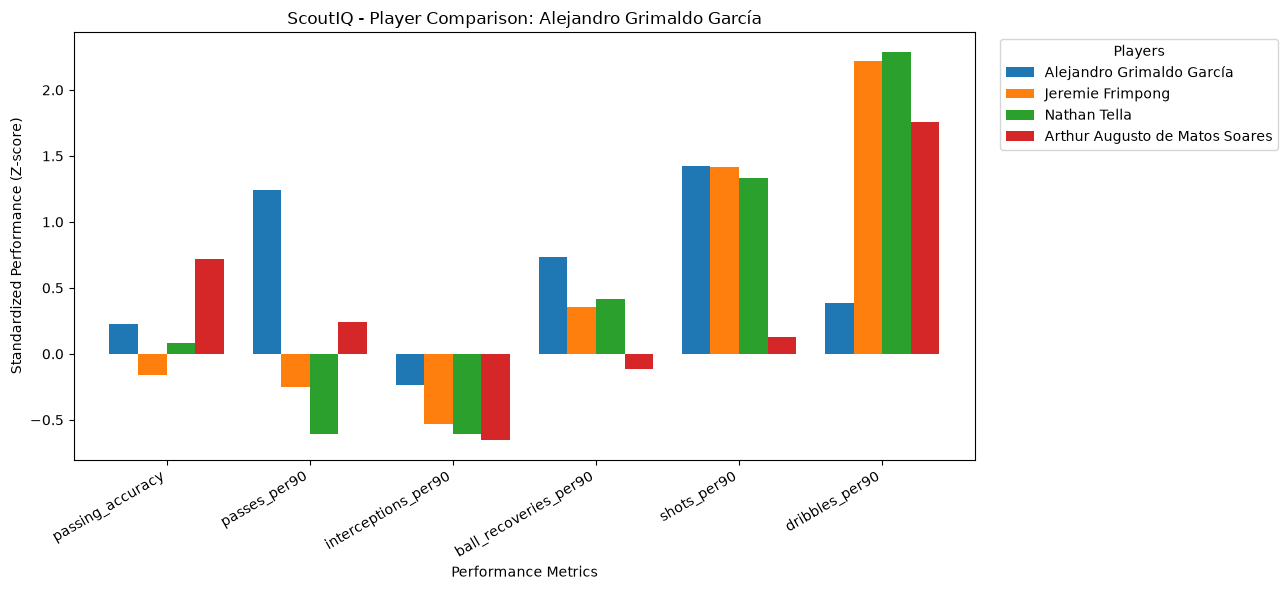

In [150]:
compare_players(
    'Alejandro Grimaldo García',
    top_n=3,
    same_group=True
)

In [151]:
final_player_stats.to_csv("scoutiq_all_players.csv", index=False)

eligible_players.to_csv("scoutiq_eligible_players.csv", index=False)

similarity_df.to_csv("scoutiq_similarity_matrix.csv")

print("ScoutIQ datasets exported successfully!")

ScoutIQ datasets exported successfully!


In [152]:
recommendations = recommend_players(
    "Alejandro Grimaldo García",
    top_n=5,
    same_group=True
)

recommendations.rename("similarity_score").to_csv(
    "scoutiq_sample_recommendations.csv"
)

print("Sample recommendations exported!")

Sample recommendations exported!
